# Paper figure: UMAP by Google Play category

This view tests whether the embedding captures **app-domain identity**. Screens are averaged per app so apps with many RICO screens do not dominate. Only the eight best-represented categories are colored; neighborhood purity is measured in the original cosine space.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

from paper_embedding_analysis import (LAYOUTS_DIR, DEFAULT_EMBEDDINGS_DIR, fit_umap, load_embeddings, output_dir, package_from_layout)

sns.set_theme(context="paper", style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RANDOM_STATE = 42
METADATA_PATH = LAYOUTS_DIR.parent / "play_store_metadata" / "app_details_enriched.csv"
EMBEDDINGS_DIR = DEFAULT_EMBEDDINGS_DIR
OUTPUT_DIR = output_dir("paper_umap_google_play_category")
N_CATEGORIES = 8
MAX_APPS_PER_CATEGORY = 250
MAX_SCREENS_PER_APP = 5
K_NEIGHBORS = 10

## Match layouts to app metadata

The global layout ID remains the embedding key. Package names are read from each layout's `activity_name`; no trace-local identifiers are involved.

In [3]:
metadata = pd.read_csv(METADATA_PATH, usecols=["App Package Name", "Play Store Name", "Category"], dtype=str)
metadata = metadata.dropna(subset=["App Package Name", "Category"]).drop_duplicates("App Package Name")
package_to_category = metadata.set_index("App Package Name")["Category"].to_dict()
package_to_name = metadata.set_index("App Package Name")["Play Store Name"].to_dict()
layout_paths = sorted(LAYOUTS_DIR.glob("*.json"), key=lambda p: int(p.stem))
with ThreadPoolExecutor(max_workers=16) as executor:
    packages = list(tqdm(executor.map(package_from_layout, layout_paths), total=len(layout_paths), desc="Reading packages"))
screen_map = pd.DataFrame({"screen_id": [int(p.stem) for p in layout_paths], "package": packages})
screen_map["category"] = screen_map["package"].map(package_to_category)
screen_map = screen_map.dropna(subset=["category"])
app_counts = screen_map.drop_duplicates("package")["category"].value_counts()
category_order = app_counts.head(N_CATEGORIES).index.tolist()
screen_map = screen_map[screen_map["category"].isin(category_order)].copy()
display(app_counts.loc[category_order].rename("RICO apps").to_frame())

Reading packages: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 66261/66261 [00:14<00:00, 4484.77it/s]


,RICO apps
category,
Entertainment,932
Social,588
Communication,584
Lifestyle,557
Books & Reference,521
Education,501
Travel & Local,431
Health & Fitness,429


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
chosen_packages = []
for category, group in screen_map.drop_duplicates("package").groupby("category"):
    packages = group["package"].to_numpy()
    chosen_packages.extend(rng.choice(packages, size=min(MAX_APPS_PER_CATEGORY, len(packages)), replace=False))
selected = (screen_map[screen_map["package"].isin(chosen_packages)]
            .sample(frac=1, random_state=RANDOM_STATE)
            .groupby("package", group_keys=False).head(MAX_SCREENS_PER_APP))
ids, vectors = load_embeddings(selected["screen_id"], EMBEDDINGS_DIR, description="Loading selected screens")
vector_by_id = dict(zip(ids, vectors))
selected["embedding"] = selected["screen_id"].map(vector_by_id)
selected = selected.dropna(subset=["embedding"])
rows = []
for package, group in selected.groupby("package"):
    rows.append({"package": package, "app_name": package_to_name.get(package), "category": group["category"].iloc[0], "n_screens": len(group), "embedding": np.stack(group["embedding"]).mean(axis=0)})
apps = pd.DataFrame(rows)
X = normalize(np.stack(apps["embedding"])).astype(np.float32)
coords, pca = fit_umap(X, random_state=RANDOM_STATE)
apps[["umap_1", "umap_2"]] = coords
print(f"{len(apps):,} apps; PC1+PC2 explain {pca.explained_variance_ratio_[:2].sum():.1%}.")

Loading selected screens: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7042/7042 [00:05<00:00, 1289.09it/s]


2,000 apps; PC1+PC2 explain 38.2%.


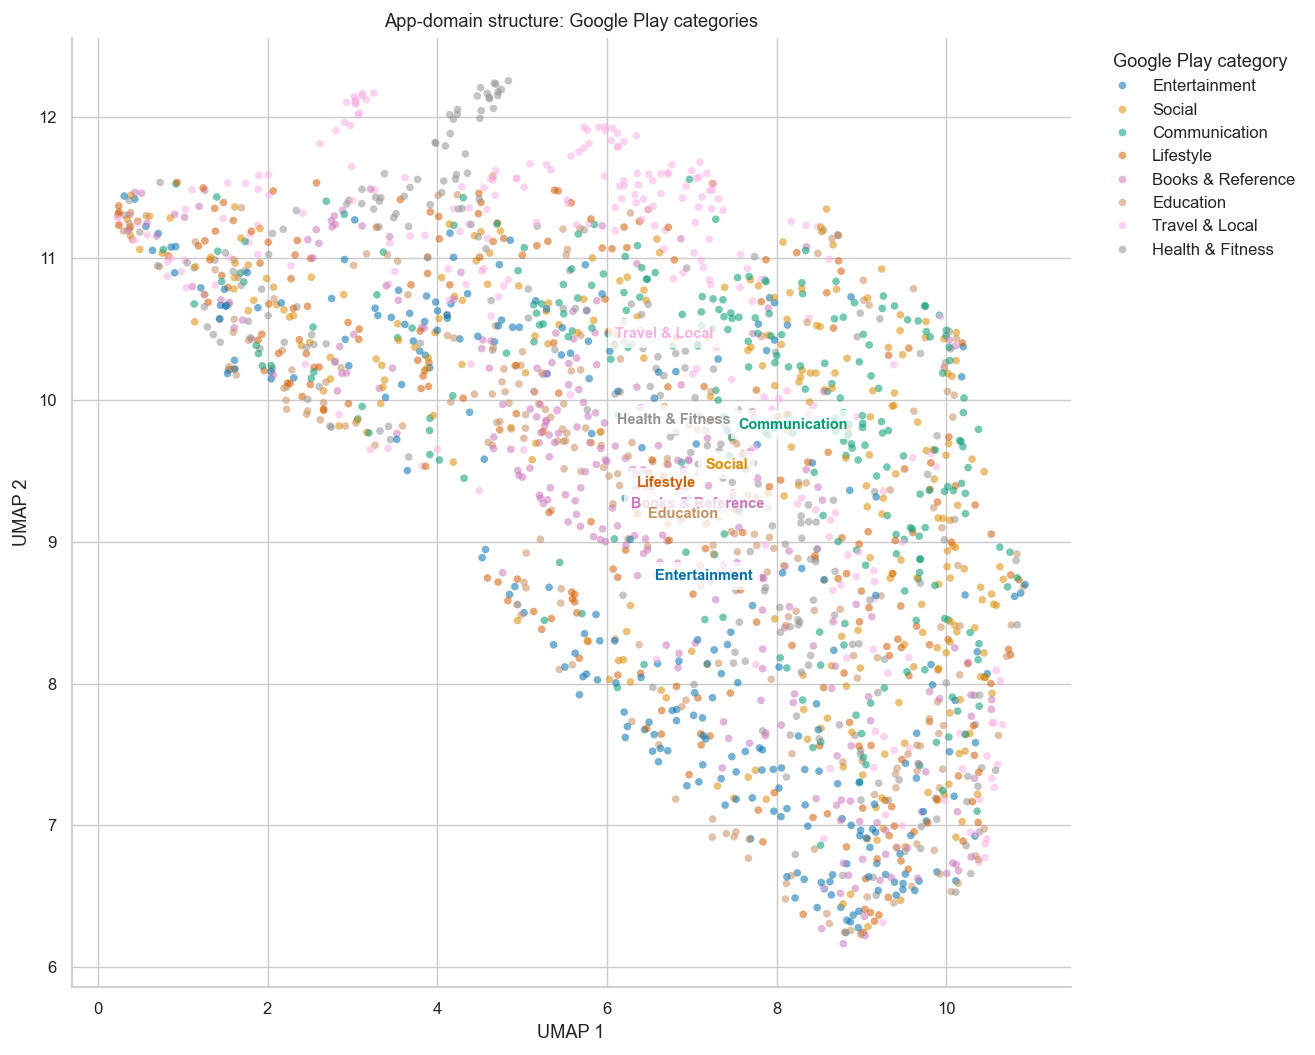

In [5]:
palette = dict(zip(category_order, sns.color_palette("colorblind", len(category_order))))
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.scatterplot(data=apps, x="umap_1", y="umap_2", hue="category", hue_order=category_order, palette=palette, s=18, alpha=0.55, linewidth=0, rasterized=True, ax=ax)
centroids = apps.groupby("category")[["umap_1", "umap_2"]].mean()
for category, point in centroids.loc[category_order].iterrows():
    ax.annotate(category, point, color=palette[category], fontsize=8, weight="bold", bbox={"fc": "white", "ec": "none", "alpha": 0.75})
ax.set(title="App-domain structure: Google Play categories", xlabel="UMAP 1", ylabel="UMAP 2")
ax.legend(title="Google Play category", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine(ax=ax)
fig.savefig(OUTPUT_DIR / "google_play_category_umap.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "google_play_category_umap.pdf", bbox_inches="tight")
plt.show()

In [6]:
labels = apps["category"].to_numpy()
neighbor_model = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1, metric="cosine").fit(X)
neighbors = neighbor_model.kneighbors(X, return_distance=False)[:, 1:]
purity = (labels[neighbors] == labels[:, None]).mean(axis=1)
result = pd.DataFrame({"category": labels, "purity": purity}).groupby("category").agg(apps=("purity", "size"), mean_purity=("purity", "mean")).sort_values("mean_purity", ascending=False)
display(result.style.format({"mean_purity": "{:.3f}"}))
apps.drop(columns="embedding").to_csv(OUTPUT_DIR / "google_play_category_umap.csv", index=False)
result.to_csv(OUTPUT_DIR / "google_play_category_purity.csv")

,apps,mean_purity
category,,
Health & Fitness,250,0.491
Travel & Local,250,0.483
Communication,250,0.447
Books & Reference,250,0.420
Education,250,0.360
Entertainment,250,0.339
Social,250,0.336
Lifestyle,250,0.159
